In [2]:
import pandas as pd
import matplotlib.pyplot as plt

I'm reading in data about 311 service requests placed from July 26, 2026 to October 26, 2026. It's nearly a million rows of data. I'm mostly interested in rodent related incidents, because I recently moved from Bed Stuy to Flatbush and I swear I see fewer rodents in my new neighborhood. But I'm also interested in graffiti requests and noise complaints.


In [3]:
data = pd.read_csv("../data/311_Service_Requests_from_2020_to_Present_20261026.csv")

/var/folders/b3/7ff3l61x4430tvnzkbtnzr0c0000gn/T/ipykernel_35265/1763056927.py:1: DtypeWarning: Columns (9,19,21,37,38,39,40) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("../data/311_Service_Requests_from_2020_to_Present_20261026.csv")


In [4]:
data.head

<bound method NDFrame.head of         Unique Key            Created Date             Closed Date Agency  \
0         70880898  10/25/2026 03:05:51 AM                     NaN   DSNY   
1         70880940  10/25/2026 01:36:20 AM                     NaN   NYPD   
2         70880941  10/25/2026 01:36:18 AM                     NaN   NYPD   
3         70872525  10/25/2026 01:35:55 AM                     NaN   NYPD   
4         70876800  10/25/2026 01:35:45 AM                     NaN   NYPD   
...            ...                     ...                     ...    ...   
984505    69847151  07/26/2026 12:00:15 AM  08/01/2026 01:03:22 PM   DSNY   
984506    69841270  07/26/2026 12:00:14 AM  07/26/2026 12:39:43 AM   NYPD   
984507    69836902  07/26/2026 12:00:12 AM  07/26/2026 01:22:12 AM   NYPD   
984508    69846670  07/26/2026 12:00:01 AM  07/26/2026 01:23:59 AM   NYPD   
984509    69845717  07/26/2026 12:00:00 AM  07/26/2026 03:39:42 AM   NYPD   

                            Agency Name Probl

The data has too much information, I don't need all of this. So I'm going to see what all the columns are and decide which I do not need. 

In [5]:
data.dtypes

Unique Key                                int64
Created Date                             object
Closed Date                              object
Agency                                   object
Agency Name                              object
Problem (formerly Complaint Type)        object
Problem Detail (formerly Descriptor)     object
Additional Details                       object
Location Type                            object
Incident Zip                             object
Incident Address                         object
Street Name                              object
Cross Street 1                           object
Cross Street 2                           object
Intersection Street 1                    object
Intersection Street 2                    object
Address Type                             object
City                                     object
Landmark                                 object
Facility Type                            object
Status                                  

In [6]:
data_refined = data[['Created Date', 'Closed Date', 'Agency', 'Problem (formerly Complaint Type)',
                     'Problem Detail (formerly Descriptor)', 'Incident Zip', 'City', 'Status', 'Council District',
                     'Borough', 'Latitude', 'Longitude'
                     ]].reset_index()

In [7]:
data_refined.head

<bound method NDFrame.head of          index            Created Date             Closed Date Agency  \
0            0  10/25/2026 03:05:51 AM                     NaN   DSNY   
1            1  10/25/2026 01:36:20 AM                     NaN   NYPD   
2            2  10/25/2026 01:36:18 AM                     NaN   NYPD   
3            3  10/25/2026 01:35:55 AM                     NaN   NYPD   
4            4  10/25/2026 01:35:45 AM                     NaN   NYPD   
...        ...                     ...                     ...    ...   
984505  984505  07/26/2026 12:00:15 AM  08/01/2026 01:03:22 PM   DSNY   
984506  984506  07/26/2026 12:00:14 AM  07/26/2026 12:39:43 AM   NYPD   
984507  984507  07/26/2026 12:00:12 AM  07/26/2026 01:22:12 AM   NYPD   
984508  984508  07/26/2026 12:00:01 AM  07/26/2026 01:23:59 AM   NYPD   
984509  984509  07/26/2026 12:00:00 AM  07/26/2026 03:39:42 AM   NYPD   

       Problem (formerly Complaint Type) Problem Detail (formerly Descriptor)  \
0           

Now I want to look at service requests related to rodents. 

In [8]:
rodent_311 = data_refined[data_refined["Problem (formerly Complaint Type)"] == "Rodent"]

Hopefully this is more readable now....

In [9]:
rodent_311

,index,Created Date,Closed Date,Agency,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Incident Zip,City,Status,Council District,Borough,Latitude,Longitude
238,238,10/25/2026 01:00:59 AM,NaN,DOHMH,Rodent,Rat Sighting,10463.0,BRONX,In Progress,11.0,BRONX,40.884118,-73.906041
315,315,10/25/2026 12:51:49 AM,NaN,DOHMH,Rodent,Rat Sighting,10463.0,BRONX,In Progress,11.0,BRONX,40.884118,-73.906041
381,381,10/25/2026 12:43:22 AM,NaN,DOHMH,Rodent,Rat Sighting,10026.0,NEW YORK,In Progress,9.0,MANHATTAN,40.798831,-73.953834
414,414,10/25/2026 12:38:20 AM,NaN,DOHMH,Rodent,Rat Sighting,10065.0,NEW YORK,In Progress,5.0,MANHATTAN,40.761640,-73.962888
633,633,10/25/2026 12:15:45 AM,NaN,DOHMH,Rodent,Mouse Sighting,11222.0,BROOKLYN,In Progress,33.0,BROOKLYN,40.728386,-73.958082
...,...,...,...,...,...,...,...,...,...,...,...,...,...
983415,983415,07/26/2026 01:38:58 AM,07/31/2026 07:01:36 PM,DOHMH,Rodent,Condition Attracting Rodents,11106.0,ASTORIA,Closed,22.0,QUEENS,40.761546,-73.925740
983727,983727,07/26/2026 01:03:55 AM,07/29/2026 07:01:03 PM,DOHMH,Rodent,Rat Sighting,11233.0,BROOKLYN,Closed,36.0,BROOKLYN,40.685081,-73.927984
983729,983729,07/26/2026 01:03:53 AM,08/25/2026 10:03:05 PM,DOHMH,Rodent,Rat Sighting,11213.0,BROOKLYN,Closed,36.0,BROOKLYN,40.673040,-73.943333
984120,984120,07/26/2026 12:29:24 AM,07/29/2026 07:00:42 PM,DOHMH,Rodent,Rat Sighting,11216.0,BROOKLYN,Closed,36.0,BROOKLYN,40.682321,-73.945427


Okay, I want to make sure that the problem is rat or mouse sightings and that there isn't other rodent-related stuff in this data, like "condition attracting rodents." So I'm going to check what's in that column. 

In [10]:
print(rodent_311['Problem Detail (formerly Descriptor)'].unique())

['Rat Sighting' 'Mouse Sighting' 'Condition Attracting Rodents'
 'Signs of Rodents']


Ok there's too much stuff in this column. I'm going to make a new data frame that takes out the signs and conditions incidents. 

In [11]:
rodent_sightings_311 = rodent_311[rodent_311['Problem Detail (formerly Descriptor)']
                                  .apply(lambda x: x == "Rat Sighting" or x== "Mouse Sighting")]




In [12]:
rodent_311_by_borough = rodent_sightings_311["Borough"].value_counts().reset_index()
print(rodent_311_by_borough)

         Borough  count
0       BROOKLYN   2306
1      MANHATTAN   1580
2         QUEENS   1153
3          BRONX    922
4  STATEN ISLAND    228
5    Unspecified      1


Interesting! I thought maybe Queens might have more rodent service requests because it's bigger than Brooklyn, though it has fewer people. Do people see more mice or rats?

In [13]:
print(rodent_sightings_311["Problem Detail (formerly Descriptor)"].value_counts().reset_index())

  Problem Detail (formerly Descriptor)  count
0                         Rat Sighting   5794
1                       Mouse Sighting    396


More rats, by far! But it's easier to see rats...they are fat....and more gross and therefore more likely to compel someone to pick up the phone and complain....and this is just the times someone called 311...

Oh, the problems with relying on data to inform your understanding of the world. 

Anyways! I am curious whether there are more rodent citings in my old neighborhood or my current one. I used to
live in Bed Stuy (11216), but now I'm in Flatbush (11226). 

In [ ]:
rodent_by_zip = rodent_sightings_311["Incident Zip"].value_counts().reset_index()

print(rodent_by_zip)

    Incident Zip  count
0        11103.0    226
1        11233.0    161
2        10027.0    150
3        11216.0    143
4        11226.0    142
..           ...    ...
219      11693.0      1
220        10306      1
221        10012      1
222        11239      1
223      10152.0      1

[224 rows x 2 columns]


Oh my god! Both of my neighborhoods are in the top 5 zip codes in all of New York City for rodent-related 311 requests. And they are almost exactly tied. There goes my hypothesis. Looks like number 1 is Astora, number 2 is that Ocean Hill area where the east sides of Bed Stuy and Crown Heights meet, and number 3 is mostly Harlem.

In [15]:
top_rodent_by_zip = rodent_by_zip.head(5).reset_index()

Let's see this data in a graph.

<Axes: xlabel='Incident Zip'>

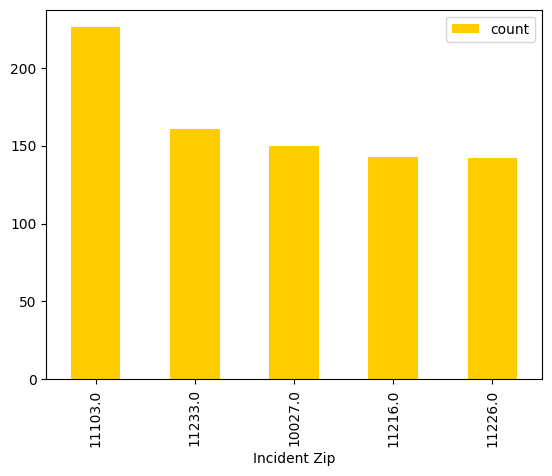

In [16]:
top_rodent_by_zip.plot(kind="bar", x="Incident Zip", y="count", color="#FFCC00")


Ok, that was fun. Let's look at a couple other types of 311 complaints. First up, graffiti. 

In [17]:
graffiti_311 = data_refined[data_refined["Problem (formerly Complaint Type)"] == "Graffiti"]

In [18]:
graffiti_311

,index,Created Date,Closed Date,Agency,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Incident Zip,City,Status,Council District,Borough,Latitude,Longitude
0,0,10/25/2026 03:05:51 AM,NaN,DSNY,Graffiti,Graffiti,10304.0,STATEN ISLAND,Open,49.0,STATEN ISLAND,40.625247,-74.075838
557,557,10/25/2026 12:23:38 AM,NaN,DSNY,Graffiti,Graffiti,10003.0,NEW YORK,Open,2.0,MANHATTAN,40.730071,-73.994274
578,578,10/25/2026 12:21:37 AM,NaN,DSNY,Graffiti,Graffiti,10003.0,NEW YORK,Open,2.0,MANHATTAN,40.730060,-73.995057
2876,2876,10/24/2026 08:39:43 PM,NaN,DSNY,Graffiti,Graffiti,10003.0,NEW YORK,Open,2.0,MANHATTAN,40.735567,-73.981171
2884,2884,10/24/2026 08:39:18 PM,10/25/2026 02:22:28 AM,DSNY,Graffiti,Graffiti,10010.0,NEW YORK,Closed,2.0,MANHATTAN,40.735767,-73.979883
...,...,...,...,...,...,...,...,...,...,...,...,...,...
980784,980784,07/26/2026 10:47:12 AM,08/31/2026 02:22:23 AM,DSNY,Graffiti,Graffiti,11249.0,BROOKLYN,Closed,34.0,BROOKLYN,40.710704,-73.964464
980852,980852,07/26/2026 10:38:12 AM,07/29/2026 12:00:00 AM,DSNY,Graffiti,Graffiti,11249.0,BROOKLYN,Closed,34.0,BROOKLYN,40.711133,-73.966545
981862,981862,07/26/2026 08:13:34 AM,07/27/2026 02:22:24 AM,DSNY,Graffiti,Graffiti,11218.0,BROOKLYN,Closed,39.0,BROOKLYN,40.646490,-73.976087
982807,982807,07/26/2026 03:17:25 AM,07/26/2026 04:16:58 AM,NYPD,Graffiti,Police Report Requested,10001.0,NEW YORK,Closed,3.0,MANHATTAN,40.751260,-73.989212


In [19]:
graffiti_311_by_borough = graffiti_311["Borough"].value_counts().reset_index()


In [20]:
graffiti_311_by_borough

,Borough,count
0,BROOKLYN,1682
1,MANHATTAN,1313
2,QUEENS,729
3,BRONX,498
4,STATEN ISLAND,251
5,Unspecified,7


Let's look at zip code info. Where do people complain about graffiti the most? This will be interesting (me constantly signposting that you should find this interesting) because the zip will have to balance between the type of people who call 311 to complain about graffiti, and there being actual graffiti to complain about. So it won't be like, the Upper East Side. 

In [21]:
graffiti_by_zip = graffiti_311["Incident Zip"].value_counts().reset_index()
print(graffiti_by_zip)

    Incident Zip  count
0        10002.0    322
1        11237.0    168
2        11211.0    163
3        11418.0    155
4        10009.0    128
..           ...    ...
179        11372      1
180        11233      1
181      10471.0      1
182      11360.0      1
183      10005.0      1

[184 rows x 2 columns]


No one complains more about graffiti or has more graffiti to complain about than the Lower East Side! It has almost two times the number of complaints as the number 2 zip, Bushwick. Williamsburg is close behind.

In [22]:
top_graffiti_by_zip = graffiti_by_zip.head(5).reset_index()

<Axes: xlabel='Incident Zip'>

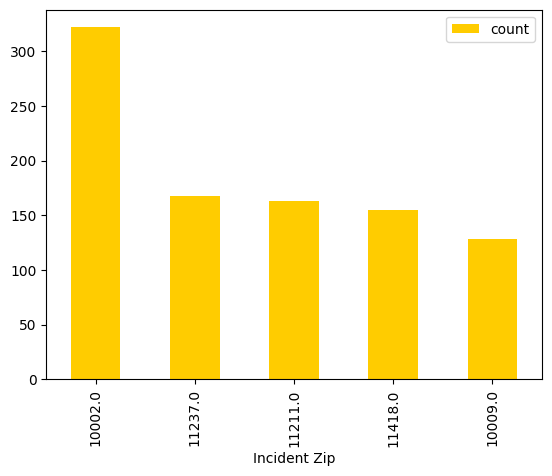

In [23]:
top_graffiti_by_zip.plot(kind="bar", x="Incident Zip", y="count", color="#FFCC00")

Ok last thing, promise. Dolly Parton once sang:

    Two doors down, they're laughin' and drinkin' and havin' a party
    Two doors down, they're not aware that I'm around
    But here I am cryin' my heart out, feeling sorry
    That they're having a party just two doors down!

What if that song had ended in her filing a noise complaint instead of walking two doors down and sleeping with the hottest guy she could find? What zip would she have likely lived in?

In [24]:
party_311 = data_refined[data_refined["Problem Detail (formerly Descriptor)"] == "Loud Music/Party"] 

In [25]:
party_by_zip = party_311["Incident Zip"].value_counts().reset_index()
party_by_zip.head(20)

,Incident Zip,count
0,10456.0,3249
1,10453.0,3172
2,10452.0,2912
3,10457.0,2575
4,10458.0,2369
5,11226.0,2345
6,10031.0,2029
7,10468.0,1902
8,11221.0,1864
9,10033.0,1823


Damn, the top 5 is entirely the Bronx, followed by my new neighborhood!

In [26]:
party_by_zip.tail(20)

,Incident Zip,count
340,10028,2
341,10007,2
342,11105,2
343,10020.0,2
344,10110.0,2
345,10075,2
346,11430.0,2
347,10121.0,2
348,10004,1
349,10179.0,1


Midtown tied for last...I wonder what that single noise complaint was. Let's look? 

In [27]:
midtown_party = data[data["Incident Zip"] == 10155.0] 

In [28]:
midtown_party

,Unique Key,Created Date,Closed Date,Agency,Agency Name,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Additional Details,Location Type,Incident Zip,...,Vehicle Type,Taxi Company Borough,Taxi Pick Up Location,Bridge Highway Name,Bridge Highway Direction,Road Ramp,Bridge Highway Segment,Latitude,Longitude,Location
433007,70424782,09/15/2026 07:49:54 PM,09/18/2026 09:30:04 AM,TLC,Taxi and Limousine Commission,Lost Property,Bag/Wallet,Backpack,Taxi,10155.0,...,NaN,NaN,"174 EAST 58 STREET, MANHATTAN (NEW YORK), NY, ...",NaN,NaN,NaN,NaN,40.761219,-73.967758,POINT (-73.967757562455 40.761219102987)
907592,69926549,08/02/2026 08:44:39 AM,08/02/2026 09:45:08 AM,NYPD,New York City Police Department,Noise - Street/Sidewalk,Loud Music/Party,NaN,Street/Sidewalk,10155.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.761480,-73.968378,POINT (-73.968378318506 40.761480025664)


Looks like it was some sidewalk thing! I want to make a DataWrapper graphic about all this rodent zip code stuff, so I am going to make three CSV files.

In [29]:
import csv

In [43]:
rodent_by_zip

,Incident Zip,count
0,11103.0,226
1,11233.0,161
2,10027.0,150
3,11216.0,143
4,11226.0,142
...,...,...
219,11693.0,1
220,10306,1
221,10012,1
222,11239,1


In [45]:
rodent_by_zip.reset_index().to_csv('rodent_zip.csv', index=False)